In [1]:
# IMPORT
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def perceptron_simple(x, w, active):
    """
    Évalue la sortie d'un perceptron simple (un neurone) pour une entrée x dans R^2.

    Paramètres :
    - x : vecteur d'entrée de taille 2 (x1, x2)
    - w : vecteur de poids de taille 3 (w0, w1, w2) où w[0] est le seuil
    - active : 0 pour sign(v), 1 pour tanh(v)

    Retourne :
    - y : scalaire, sortie du neurone
    """
    # Construction de l'entrée augmentée x_tilde = (1, x1, x2)
    x_tilde = np.array([1.0, x[0], x[1]])

    # Calcul du potentiel v = w^T * x_tilde
    v = np.dot(w, x_tilde)

    # Application de la fonction d'activation
    if active == 0:
        # np.sign renvoie -1 si v < 0, +1 si v > 0 (et 1 si v == 0 par convention binaire)
        y = 1.0 if v >= 0 else -1.0
    elif active == 1:
        y = np.tanh(v)
    else:
        raise ValueError("Le paramètre 'active' doit valoir 0 (sign) ou 1 (tanh).")

    return float(y)

--- Test du Perceptron Simple sur le OU logique ---
Entrée x = [0. 0.] -> Sortie prédite y = -1 (Attendu : -1)
Entrée x = [0. 1.] -> Sortie prédite y = +1 (Attendu : +1)
Entrée x = [1. 0.] -> Sortie prédite y = +1 (Attendu : +1)
Entrée x = [1. 1.] -> Sortie prédite y = +1 (Attendu : +1)


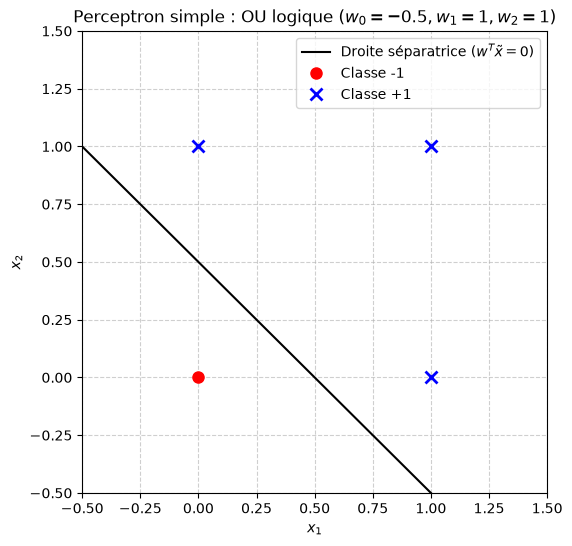

In [3]:
# 1. Définition de l'ensemble d'apprentissage du OU logique
# Format 2 x 4 (un individu par colonne, comme attendu par le code du sujet)
X_ou = np.array([
    [0, 0, 1, 1],  # x1
    [0, 1, 0, 1]   # x2
], dtype=float)

# Sorties désirées : -1 pour (0,0) et +1 sinon
yd_ou = np.array([-1, 1, 1, 1])

# Poids donnés dans l'énoncé : w0 = -0.5, w1 = 1, w2 = 1
w_ou = np.array([-0.5, 1.0, 1.0])

# 2. Test du perceptron sur les 4 exemples avec active = 0 (sign)
print("--- Test du Perceptron Simple sur le OU logique ---")
for i in range(X_ou.shape[1]):
    x_i = X_ou[:, i]
    y_pred = perceptron_simple(x_i, w_ou, active=0)
    print(f"Entrée x = {x_i} -> Sortie prédite y = {y_pred:+.0f} (Attendu : {yd_ou[i]:+d})")

# 3. Affichage des points et de la droite séparatrice (code de l'énoncé)
t = np.array([-0.5, 1.5])                 # abscisses x1 du tracé
z = -(w_ou[0] + w_ou[1] * t) / w_ou[2]    # ordonnées x2 correspondantes

plt.figure(figsize=(6, 6))
plt.plot(t, z, 'k-', label='Droite séparatrice ($w^T\\tilde{x} = 0$)')
plt.plot(X_ou[0, yd_ou == -1], X_ou[1, yd_ou == -1], 'ro', markersize=8, label='Classe -1')
plt.plot(X_ou[0, yd_ou == 1], X_ou[1, yd_ou == 1], 'bx', markersize=8, markeredgewidth=2, label='Classe +1')

plt.xlim(t[0], t[1])
plt.ylim(-0.5, 1.5)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Perceptron simple : OU logique ($w_0=-0.5, w_1=1, w_2=1$)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def apprentissage_widrow(x, yd, epoch, batch_size):
    alpha = 0.1
    N = x.shape[1]

    # Ajout de l'entrée constante pour le biais
    X = np.vstack((np.ones(N), x))

    # Initialisation aléatoire des poids
    w = np.random.uniform(-0.5, 0.5, 3)

    erreurs = []

    for e in range(epoch):
        erreur_epoch = 0

        # Mélange des individus à chaque époque
        indices = np.random.permutation(N)

        for debut in range(0, N, batch_size):
            batch = indices[debut:debut + batch_size]

            delta_w = np.zeros(3)

            for i in batch:
                xi = X[:, i]

                # Calcul de la sortie du neurone
                v = np.dot(w, xi)
                y = np.tanh(v)

                # Erreur quadratique
                erreur_epoch += (yd[i] - y) ** 2

                # Règle de Widrow-Hoff
                delta_w += alpha * (yd[i] - y) * (1 - y**2) * xi

            # Mise à jour après chaque lot
            w += delta_w

        erreurs.append(erreur_epoch)

        # Prédictions avec sign
        predictions = np.where(w @ X >= 0, 1, -1)
        nb_erreurs = np.sum(predictions != yd)

        print(f"Époque {e+1} : {nb_erreurs} mal classés")

        # Affichage de la frontière à certaines époques
        if e == 0 or (e + 1) % 10 == 0 or nb_erreurs == 0:
            afficher_frontiere(x, yd, w, e + 1)

        # Arrêt lorsque tous les individus sont bien classés
        if nb_erreurs == 0:
            break

    return w, np.array(erreurs)

def afficher_frontiere(x, yd, w, epoque):
    plt.figure(figsize=(7, 5))

    plt.scatter(
        x[0, yd == -1],
        x[1, yd == -1],
        label="Classe -1",
        marker="o"
    )

    plt.scatter(
        x[0, yd == 1],
        x[1, yd == 1],
        label="Classe +1",
        marker="x"
    )

    # Droite : w0 + w1*x1 + w2*x2 = 0
    t = np.linspace(x[0].min(), x[0].max(), 100)

    if abs(w[2]) > 1e-12:
        z = -(w[0] + w[1] * t) / w[2]
        plt.plot(t, z, "k-", label="Frontière")
    elif abs(w[1]) > 1e-12:
        plt.axvline(-w[0] / w[1], color="black", label="Frontière")

    plt.xlim(x[0].min() - 0.5, x[0].max() + 0.5)
    plt.ylim(x[1].min() - 0.5, x[1].max() + 0.5)

    plt.title(f"Frontière de décision - Époque {epoque}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.show()

In [5]:
def afficher_frontiere(x, yd, w, epoque):
    plt.figure(figsize=(7, 5))

    plt.scatter(
        x[0, yd == -1],
        x[1, yd == -1],
        label="Classe -1",
        marker="o"
    )

    plt.scatter(
        x[0, yd == 1],
        x[1, yd == 1],
        label="Classe +1",
        marker="x"
    )

    # Droite : w0 + w1*x1 + w2*x2 = 0
    t = np.linspace(x[0].min(), x[0].max(), 100)

    if abs(w[2]) > 1e-12:
        z = -(w[0] + w[1] * t) / w[2]
        plt.plot(t, z, "k-", label="Frontière")
    elif abs(w[1]) > 1e-12:
        plt.axvline(-w[0] / w[1], color="black", label="Frontière")

    plt.xlim(x[0].min() - 0.5, x[0].max() + 0.5)
    plt.ylim(x[1].min() - 0.5, x[1].max() + 0.5)

    plt.title(f"Frontière de décision - Époque {epoque}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.show()

Époque 1 : 0 mal classés


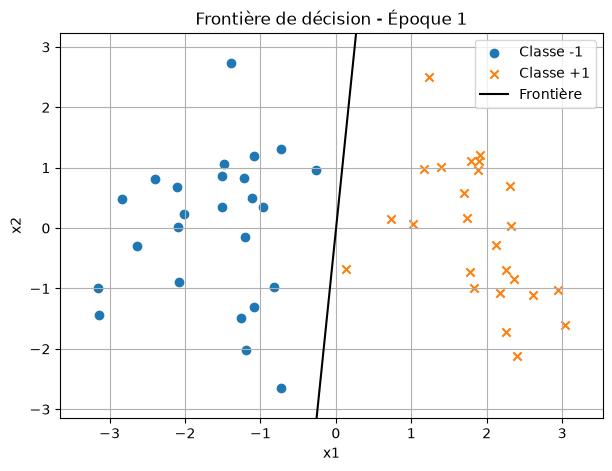

Poids finaux : [-0.00291336  0.93391293 -0.07672586]


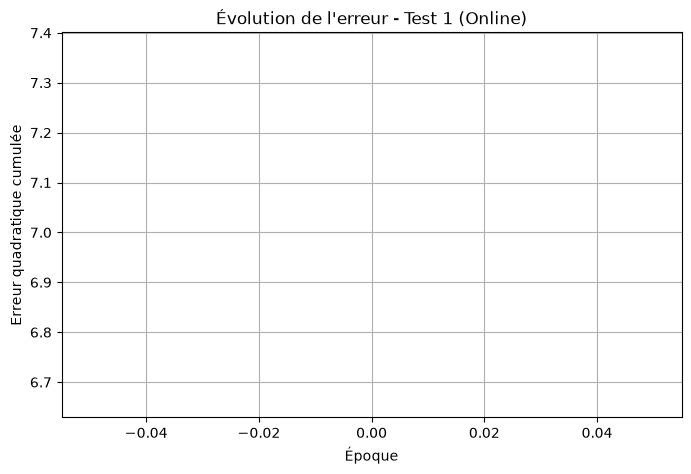

In [18]:
# Chargement des données
X = np.loadtxt("p2_d1.txt")

# 25 individus de chaque classe
yd = np.concatenate((-np.ones(25), np.ones(25)))

# Apprentissage online
w_online, erreur_online = apprentissage_widrow(
    X, yd, epoch=100, batch_size=1
)

print("Poids finaux :", w_online)

# Évolution de l'erreur
plt.figure(figsize=(8, 5))
plt.plot(erreur_online)
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur - Test 1 (Online)")
plt.grid(True)
plt.show()

Époque 1 : 1 mal classés


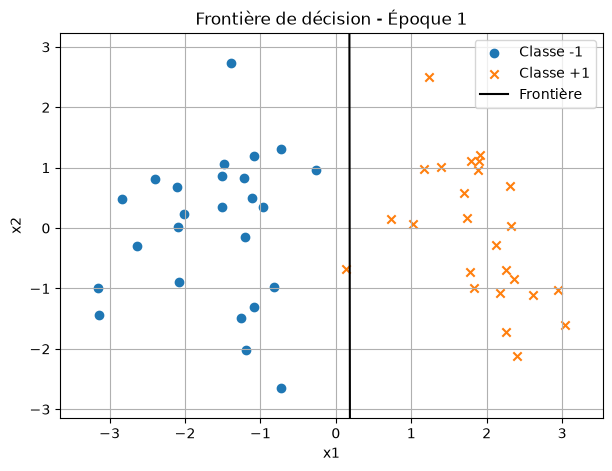

Époque 2 : 0 mal classés


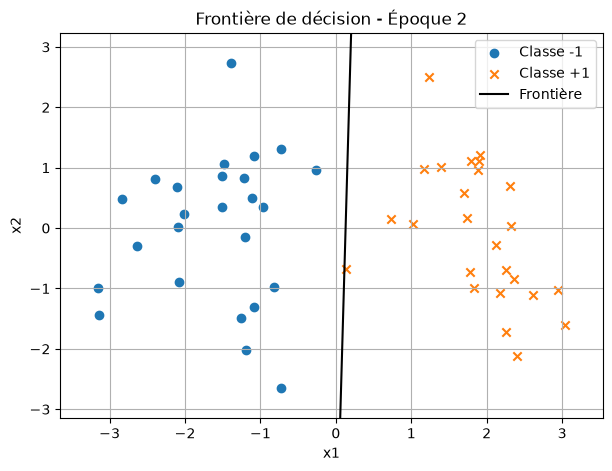

Poids finaux : [-0.14699011  1.13761565 -0.02581033]


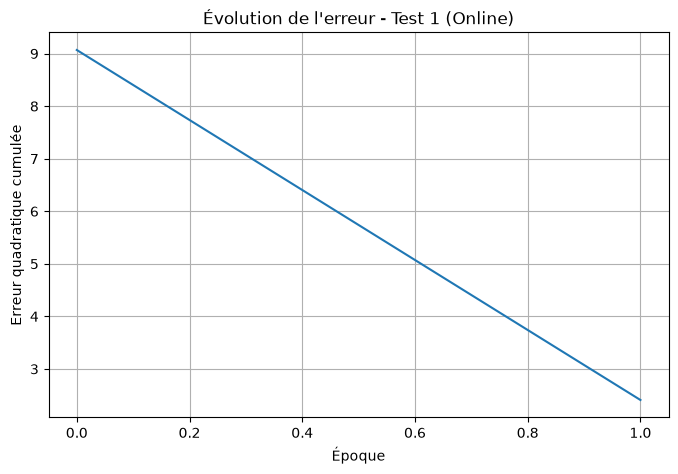

In [19]:
# Chargement des données
X = np.loadtxt("p2_d1.txt")

# 25 individus de chaque classe
yd = np.concatenate((-np.ones(25), np.ones(25)))

# Apprentissage online
w_online, erreur_online = apprentissage_widrow(
    X, yd, epoch=100, batch_size=1
)

print("Poids finaux :", w_online)

# Évolution de l'erreur
plt.figure(figsize=(8, 5))
plt.plot(erreur_online)
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur - Test 1 (Online)")
plt.grid(True)
plt.show()

Époque 1 : 0 mal classés


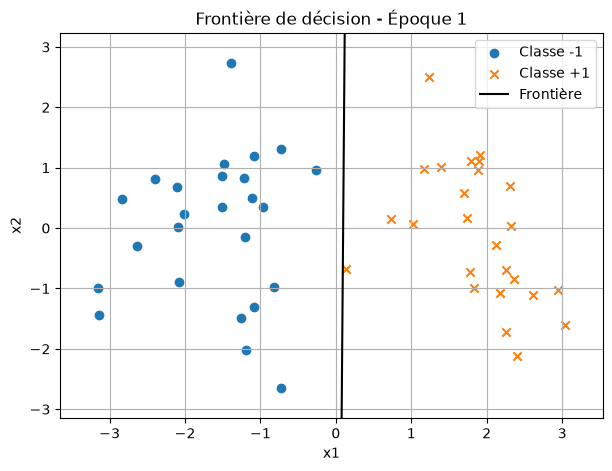

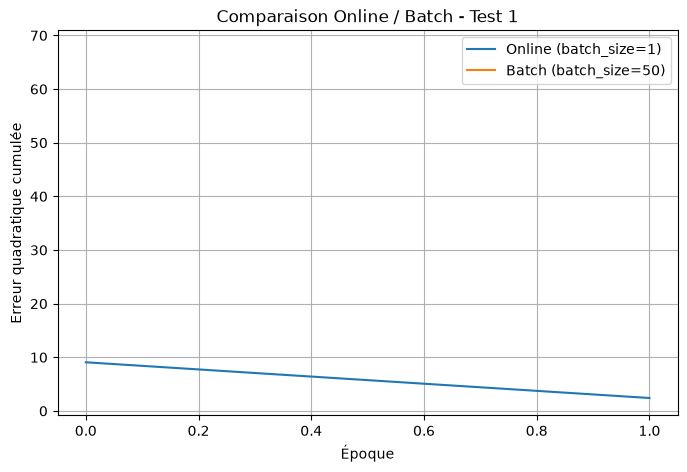

In [20]:
w_batch, erreur_batch = apprentissage_widrow(
    X, yd, epoch=100, batch_size=50
)

plt.figure(figsize=(8, 5))

plt.plot(erreur_online, label="Online (batch_size=1)")
plt.plot(erreur_batch, label="Batch (batch_size=50)")

plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Comparaison Online / Batch - Test 1")
plt.legend()
plt.grid(True)
plt.show()

Époque 1 : 3 mal classés


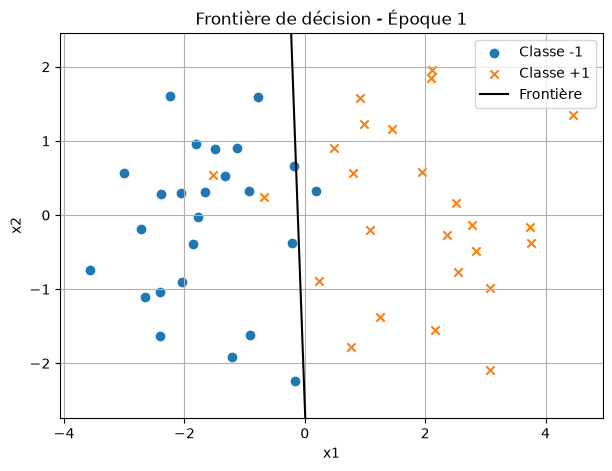

Époque 2 : 3 mal classés
Époque 3 : 4 mal classés
Époque 4 : 4 mal classés
Époque 5 : 4 mal classés
Époque 6 : 3 mal classés
Époque 7 : 3 mal classés
Époque 8 : 3 mal classés
Époque 9 : 3 mal classés
Époque 10 : 3 mal classés


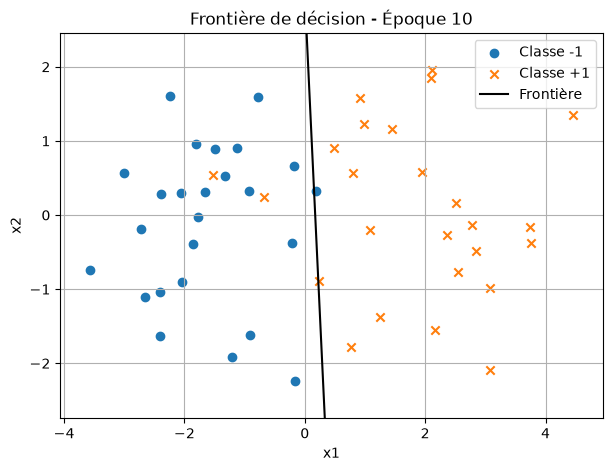

Époque 11 : 3 mal classés
Époque 12 : 3 mal classés
Époque 13 : 3 mal classés
Époque 14 : 3 mal classés
Époque 15 : 2 mal classés
Époque 16 : 3 mal classés
Époque 17 : 3 mal classés
Époque 18 : 2 mal classés
Époque 19 : 3 mal classés
Époque 20 : 3 mal classés


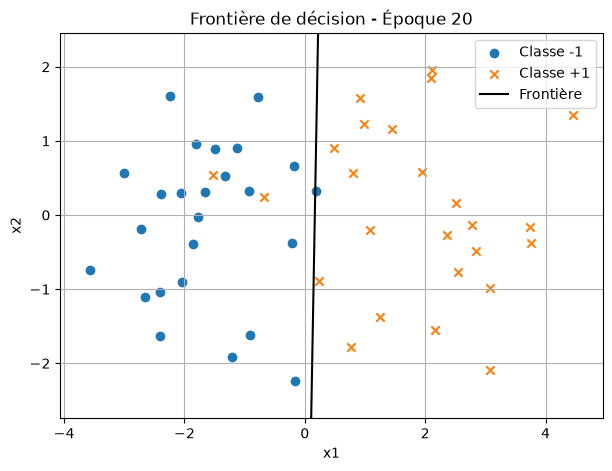

Époque 21 : 3 mal classés
Époque 22 : 3 mal classés
Époque 23 : 3 mal classés
Époque 24 : 2 mal classés
Époque 25 : 2 mal classés
Époque 26 : 2 mal classés
Époque 27 : 2 mal classés
Époque 28 : 2 mal classés
Époque 29 : 2 mal classés
Époque 30 : 2 mal classés


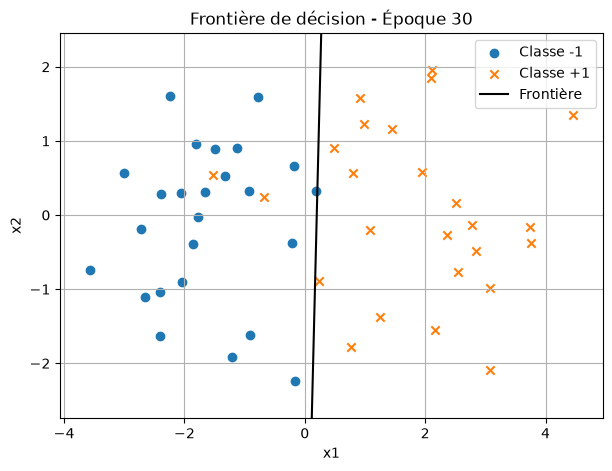

Époque 31 : 2 mal classés
Époque 32 : 2 mal classés
Époque 33 : 2 mal classés
Époque 34 : 2 mal classés
Époque 35 : 2 mal classés
Époque 36 : 2 mal classés
Époque 37 : 2 mal classés
Époque 38 : 2 mal classés
Époque 39 : 2 mal classés
Époque 40 : 2 mal classés


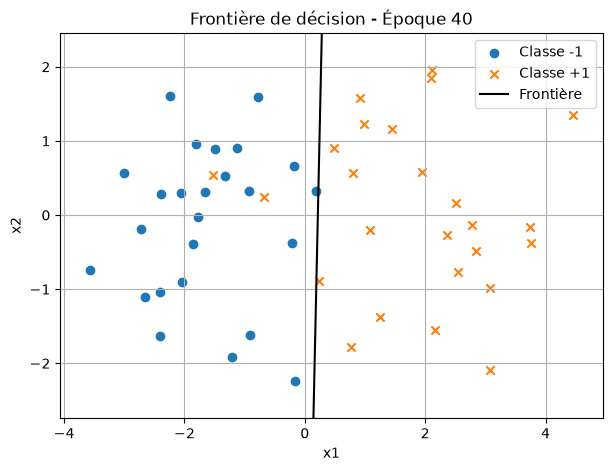

Époque 41 : 2 mal classés
Époque 42 : 2 mal classés
Époque 43 : 2 mal classés
Époque 44 : 2 mal classés
Époque 45 : 2 mal classés
Époque 46 : 2 mal classés
Époque 47 : 2 mal classés
Époque 48 : 2 mal classés
Époque 49 : 2 mal classés
Époque 50 : 2 mal classés


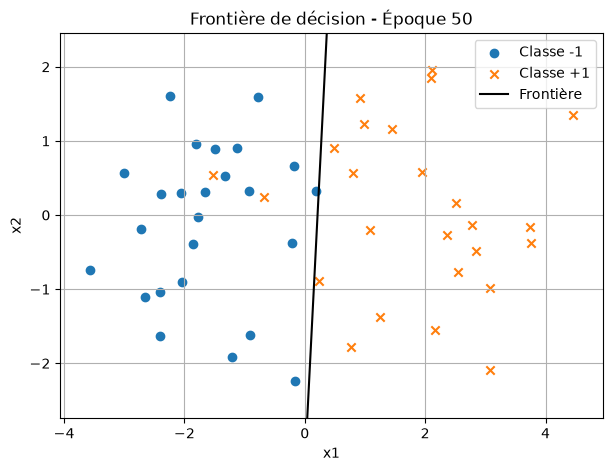

Époque 51 : 2 mal classés
Époque 52 : 2 mal classés
Époque 53 : 2 mal classés
Époque 54 : 2 mal classés
Époque 55 : 2 mal classés
Époque 56 : 2 mal classés
Époque 57 : 2 mal classés
Époque 58 : 2 mal classés
Époque 59 : 2 mal classés
Époque 60 : 2 mal classés


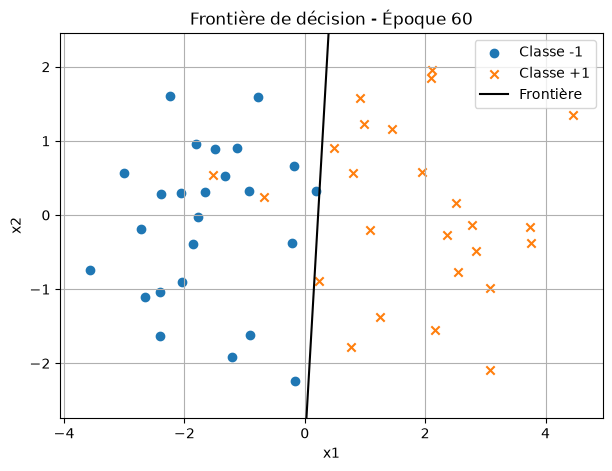

Époque 61 : 2 mal classés
Époque 62 : 2 mal classés
Époque 63 : 2 mal classés
Époque 64 : 2 mal classés
Époque 65 : 2 mal classés
Époque 66 : 2 mal classés
Époque 67 : 2 mal classés
Époque 68 : 2 mal classés
Époque 69 : 2 mal classés
Époque 70 : 2 mal classés


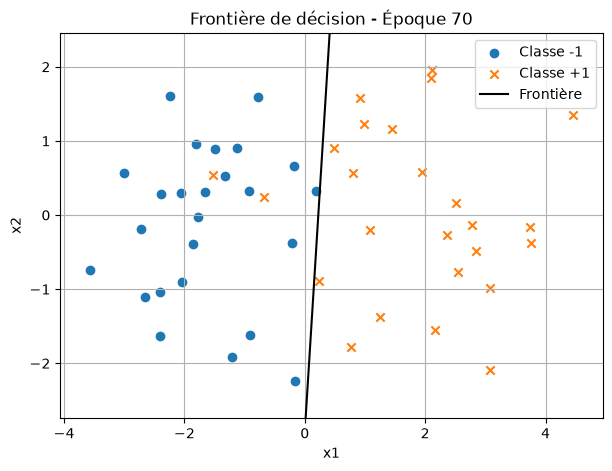

Époque 71 : 2 mal classés
Époque 72 : 2 mal classés
Époque 73 : 2 mal classés
Époque 74 : 2 mal classés
Époque 75 : 2 mal classés
Époque 76 : 2 mal classés
Époque 77 : 2 mal classés
Époque 78 : 2 mal classés
Époque 79 : 2 mal classés
Époque 80 : 2 mal classés


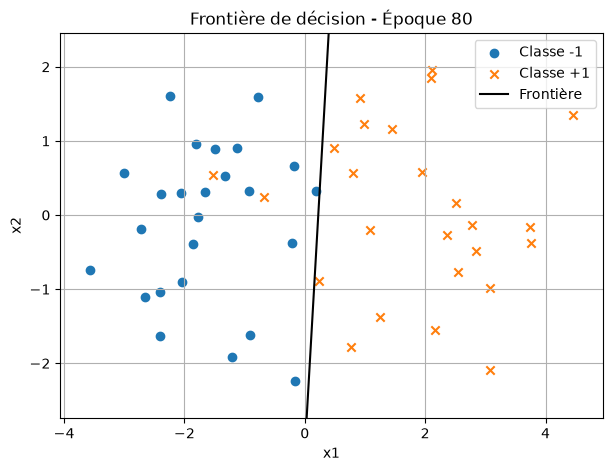

Époque 81 : 2 mal classés
Époque 82 : 2 mal classés
Époque 83 : 2 mal classés
Époque 84 : 2 mal classés
Époque 85 : 2 mal classés
Époque 86 : 2 mal classés
Époque 87 : 2 mal classés
Époque 88 : 2 mal classés
Époque 89 : 2 mal classés
Époque 90 : 2 mal classés


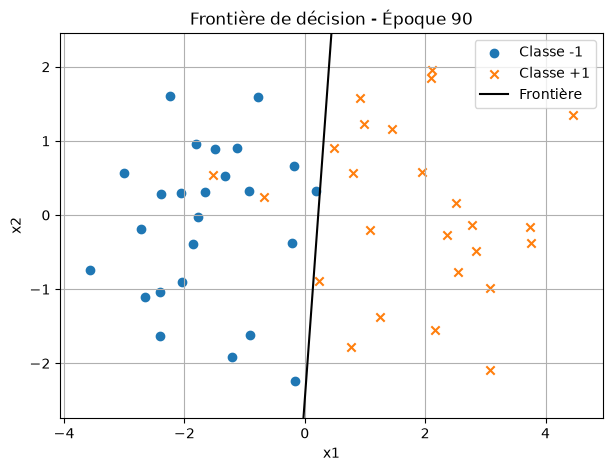

Époque 91 : 2 mal classés
Époque 92 : 2 mal classés
Époque 93 : 2 mal classés
Époque 94 : 2 mal classés
Époque 95 : 2 mal classés
Époque 96 : 2 mal classés
Époque 97 : 2 mal classés
Époque 98 : 2 mal classés
Époque 99 : 2 mal classés
Époque 100 : 2 mal classés


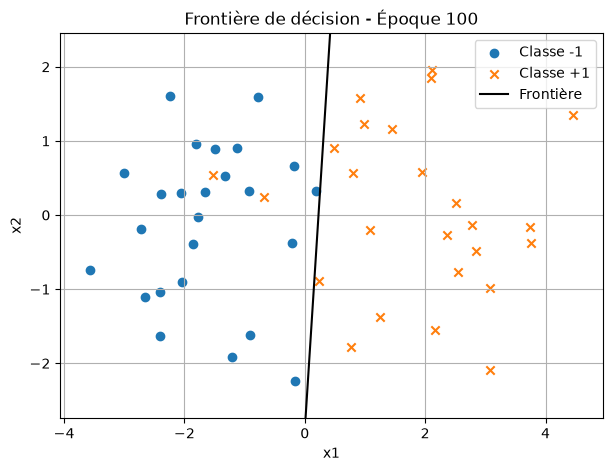

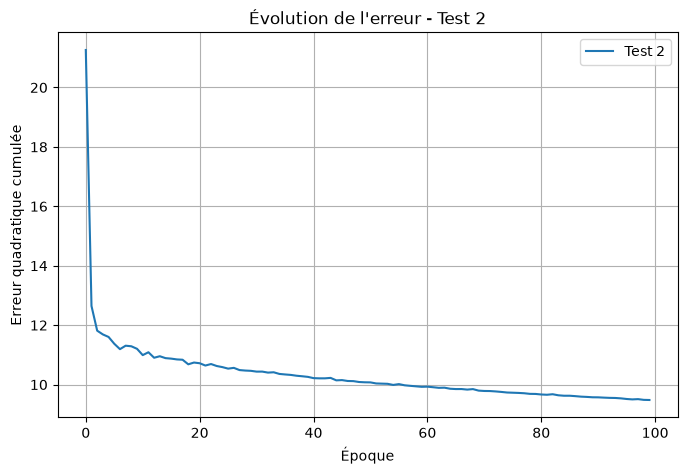

In [21]:
X2 = np.loadtxt("p2_d2.txt")

yd2 = np.concatenate((-np.ones(25), np.ones(25)))

w2, erreur2 = apprentissage_widrow(
    X2, yd2, epoch=100, batch_size=1
)

plt.figure(figsize=(8, 5))

plt.plot(erreur2, label="Test 2")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur - Test 2")
plt.legend()
plt.grid(True)
plt.show()